# WRDS validation of retirement portfolio allocation

**November 19, 2026 | Extension of the Tanish/Wedmont implementation audit**

We investigate whether the withdrawal-success frontier and the value of conditioning allocation on
planned cash flows survive a change in return measurement. This extension replaces reconstructed
Treasury returns with CRSP target-maturity Treasury returns, then replaces the remaining core inputs.
The analysis is retrospective and follows the public-data results; it is not a new preregistered test.

The object of study is a portfolio rule under specified withdrawals and preferences. These market-return
data contain no household age, reported risk tolerance, or household balance sheets. Accordingly, this
analysis cannot estimate the population relationship between age and risk tolerance or financial capacity.
The earlier household-survey work addresses a different empirical question.


In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'backend/lifecycle').exists())
OUT = ROOT/'research/wrds_validation_2026_11_19'
FIG = OUT/'figures'
FIG.mkdir(exist_ok=True)
def read(name):
    return json.loads((OUT/name).read_text(encoding='utf-8'))
def result(record):
    return read(record['run_id']+'.json')
def export(name):
    plt.savefig(FIG/(name+'.png'),dpi=180,bbox_inches='tight')
    plt.show()
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
labels = {'public':'Public reconstructed Treasury','treasury_only':'CRSP Treasury only','wrds':'All CRSP core inputs'}
runs = {d:read(d+'_frontier_runs.json') for d in labels}
extended = read('wrds_extended_runs.json')


## Data sources and selection

CRSP Treasury and Inflation Indexes (`crsp.mcti`) provide Treasury target-maturity returns, a one-month
bill return and CPI inflation. `crsp.msix.vwretd` supplies the US value-weighted equity return including
distributions. These extracts end in December 2024. Treasury return histories start in 1941; the common
long calibration begins in May 1953, the first month available for the public Treasury reconstruction.

The CRSP methodology selects a representative issue near each target maturity. It is an observed
security-return series assembled under an index methodology, rather than the project's yield-based
par-bond reconstruction. It also differs from IEF, which holds a portfolio of securities with maturities
of seven to ten years. This choice tests the sensitivity to Treasury measurement without treating the
two definitions as identical. See the [CRSP data descriptions, section 3.4](https://wrds-www.wharton.upenn.edu/documents/399/Data_Descriptions_Guide.pdf).

The ETF extract uses `crsp.msf_v2.mthret`, with distributions included, and ends in December 2025.
Each requested ticker resolves to one PERMNO during the extracted period. Ten funds cover international
and emerging equities, intermediate and long Treasuries, investment-grade and high-yield credit,
TIPS, real estate, gold and commodities. Published inception dates restrict the extraction to the intended
funds. First fund months may be partial; none enters the matched core frontier experiment. Portfolio
comparisons start in December 2004 for the Permanent Portfolio and May 2007 for the full universe,
after the youngest required fund's first partial month.

WRDS Bond Returns supplies a supplementary credit aggregation, August 2002 to May 2026. We use
immediately previous-month ratings and amount outstanding, exclude gaps in consecutive months, and
retain bonds with a nonmissing current return and positive lagged weight. IG uses rating numbers 1-10;
HY uses 11-21. These are lagged par-amount-weighted research portfolios, not market-value-weighted
investable indexes. Missing returns and the data provider's bond coverage can affect them.
The canonical panel selects TRACE-derived IG and the observed HYG fund for HY under its source-priority
rule; the supplementary TRACE HY aggregate is not used by the reported full-universe allocation study.

Raw licensed observations remain local and excluded from Git and the report package. This notebook reads
only aggregate results and coverage metadata. Sources: [WRDS CRSP product documentation](https://wrds-www.wharton.upenn.edu/pages/about/data-vendors/center-for-research-in-security-prices-crsp/),
[WRDS Bond Returns product description](https://wrds-www.wharton.upenn.edu/pages/analytics/).


In [2]:
audit = pd.read_csv(OUT/'source_audit.csv')
selected = ['us_eq','ust_2y','ust_5y','ust_10y','ust_30y','tbill','cpi_nsa','ust_7_10_etf','gold','ig_credit','hy_credit']
display(audit[audit.series_id.isin(selected)].reset_index(drop=True))
assert audit['nonfinite'].sum()==0 and audit['duplicates'].sum()==0
summary = read('extraction_summary.json')
checks = pd.DataFrame(summary['sources']['mcti']['unit_checks_against_index_growth']).T
display(checks)
assert (checks.decimal_rmse < checks.percent_rmse).all()
display(Markdown('Return/index reconciliation supports decimal return units. CPI index levels have lower precision, so their reconciliation residual is larger. Core series have no internal missing months.'))
display(pd.read_csv(OUT/'source_difference_summary.csv').round(6))


,series_id,source,months,start,end,internal_missing_months,nonfinite,duplicates
0,cpi_nsa,wrds:crsp.mcti.cpiret,1188,1926-01-31,2024-12-31,0,0,0
1,gold,wrds:crsp.msf_v2.mthret.GLD,254,2004-11-30,2025-12-31,0,0,0
2,hy_credit,wrds:crsp.msf_v2.mthret.HYG,225,2007-04-30,2025-12-31,0,0,0
3,ig_credit,wrds:wrdsapps_bondret.lagged_rating_amount.ig,286,2002-08-31,2026-05-31,0,0,0
4,tbill,wrds:crsp.mcti.t30ret,1188,1926-01-31,2024-12-31,0,0,0
5,us_eq,wrds:crsp.msix.vwretd,1188,1926-01-31,2024-12-31,0,0,0
6,ust_10y,wrds:crsp.mcti.b10ret,1004,1941-05-31,2024-12-31,0,0,0
7,ust_2y,wrds:crsp.mcti.b2ret,1008,1941-01-31,2024-12-31,0,0,0
8,ust_30y,wrds:crsp.mcti.b30ret,998,1941-11-30,2024-12-31,0,0,0
9,ust_5y,wrds:crsp.mcti.b5ret,1005,1941-04-30,2024-12-31,0,0,0


,decimal_rmse,percent_rmse,n
b2ret,2.759560e-07,0.008226,1008.0
b5ret,2.610594e-07,0.014031,1005.0
b10ret,2.686825e-07,0.020259,1004.0
b20ret,2.714298e-07,0.027172,996.0
b30ret,2.640101e-07,0.031217,998.0
t30ret,3.120696e-07,0.003642,1188.0
cpiret,5.442194e-04,0.005757,1188.0


Return/index reconciliation supports decimal return units. CPI index levels have lower precision, so their reconciliation residual is larger. Core series have no internal missing months.

,series_id,window,n_months,public_annualized_arithmetic_mean,wrds_annualized_arithmetic_mean,monthly_return_correlation,monthly_difference_rmse
0,us_eq,long,860,0.118666,0.116117,0.998977,0.001980
1,us_eq,modern,268,0.117681,0.113225,0.997601,0.003120
2,ust_10y,long,860,0.054180,0.055298,0.702600,0.015653
3,ust_10y,modern,268,0.030804,0.032399,0.718399,0.015033
4,tbill,long,860,0.040591,0.040492,0.995469,0.000244
5,tbill,modern,268,0.015018,0.014978,0.997037,0.000115
6,cpi_nsa,long,860,0.034640,0.034640,1.000000,0.000000
7,cpi_nsa,modern,268,0.025088,0.025088,1.000000,0.000000


## Matched source experiment

We run three panels over exactly the same calendar windows: the public baseline, a panel replacing only
Treasury returns with CRSP, and a panel replacing Treasury, equity, cash and inflation with CRSP.
The Treasury-only comparison isolates that source change; the all-CRSP comparison changes four inputs
jointly. No observations are spliced across providers, and missing values are never filled.

Each frontier uses 10,000 bootstrap evaluation paths, 5,000 training paths, seed 20261119, annual
rebalancing, a 0%-100% bond grid in 5-percentage-point steps, and annual real withdrawals of 3%-6% of
initial wealth. The horizon is 30 years for both success and utility calculations. Trading costs are zero
in this matched experiment. A Student-t generator provides an additional scenario comparison.

Success means fully funding all planned withdrawals over the horizon. The minimum bond share is the
lowest tested allocation reaching 90% success. An empty value means that no allocation on the grid
reaches that target. The frontier is not assumed monotone: a zero minimum does not imply every larger
bond allocation is feasible. Bootstrap threshold intervals use 300 resamples of simulation paths and
condition on the fitted return generator. They do not include uncertainty about the historical sample,
regimes, costs or future market structure. Maximizing reported success across the evaluation grid is
descriptive; the separately trained objective comparison below provides independent policy evaluation.


,dataset,window,withdrawal_rate,best_success,all_equity_success,minimum_bond_share,status,conditional_bond_q05,conditional_bond_q95,bootstrap_infeasible_fraction,run_id,catalog_hash
2,public,long,0.05,0.8639,0.8634,NaN,no_feasible_allocation,NaN,NaN,1.0000,d8c0ccdb5bc87defc7b6,3bbcce4a7278f089
6,public,modern,0.05,0.9131,0.9131,0.0,no_bonds_needed,0.00,0.00,0.0000,6ff862dde136e0dcc811,3bbcce4a7278f089
10,public,early,0.05,0.8923,0.8213,NaN,no_feasible_allocation,0.50,0.50,0.9967,0022526d6e21f6d3bede,3bbcce4a7278f089
14,public,recent,0.05,0.9760,0.9760,0.0,no_bonds_needed,0.00,0.00,0.0000,7611a3ec4f17da7523d5,3bbcce4a7278f089
18,treasury_only,long,0.05,0.8647,0.8625,NaN,no_feasible_allocation,NaN,NaN,1.0000,f9bd3b164a72171b66eb,cac766f9337d97dc
22,treasury_only,modern,0.05,0.9126,0.9124,0.0,no_bonds_needed,0.00,0.00,0.0000,5989a1b0cc787cb5a2a5,cac766f9337d97dc
26,treasury_only,early,0.05,0.9071,0.8321,0.4,identified,0.35,0.45,0.0033,956868fe978aa78e2b5b,cac766f9337d97dc
30,treasury_only,recent,0.05,0.9768,0.9768,0.0,no_bonds_needed,0.00,0.00,0.0000,0e6c834d0705fa2b5fb0,cac766f9337d97dc
34,wrds,long,0.05,0.8565,0.8536,NaN,no_feasible_allocation,NaN,NaN,1.0000,5ed2a2bb125f27cca2cb,c1f8e3775eab9dd7
38,wrds,modern,0.05,0.8873,0.8864,NaN,no_feasible_allocation,NaN,NaN,1.0000,ee4f60305754609b50ab,c1f8e3775eab9dd7


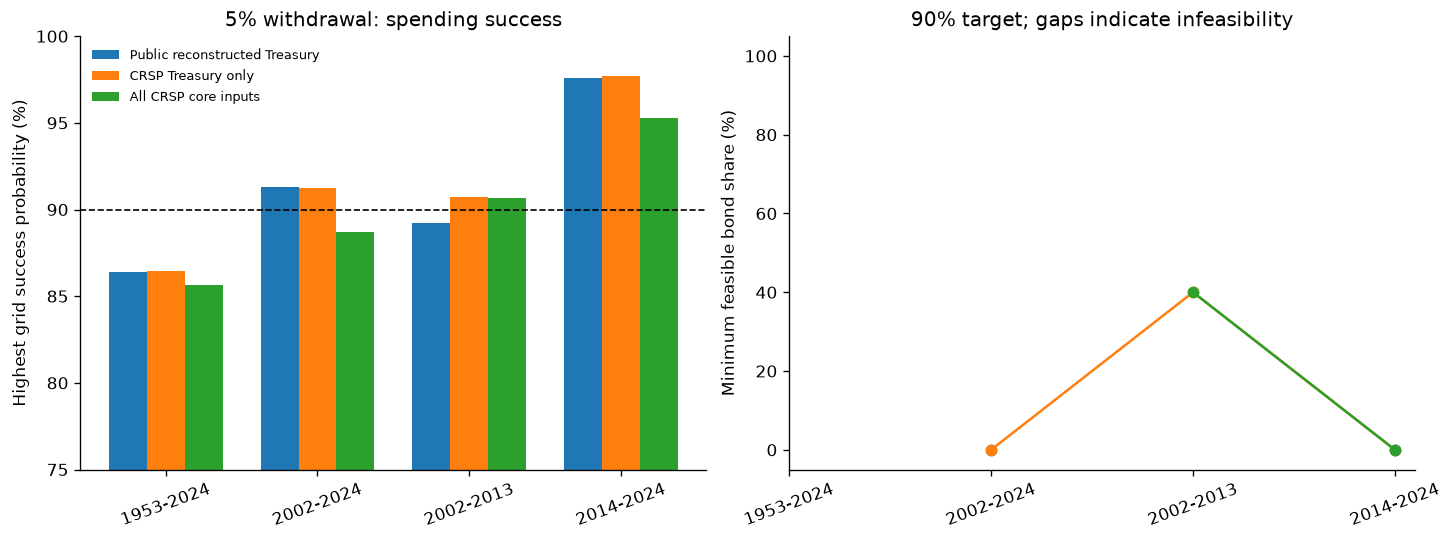

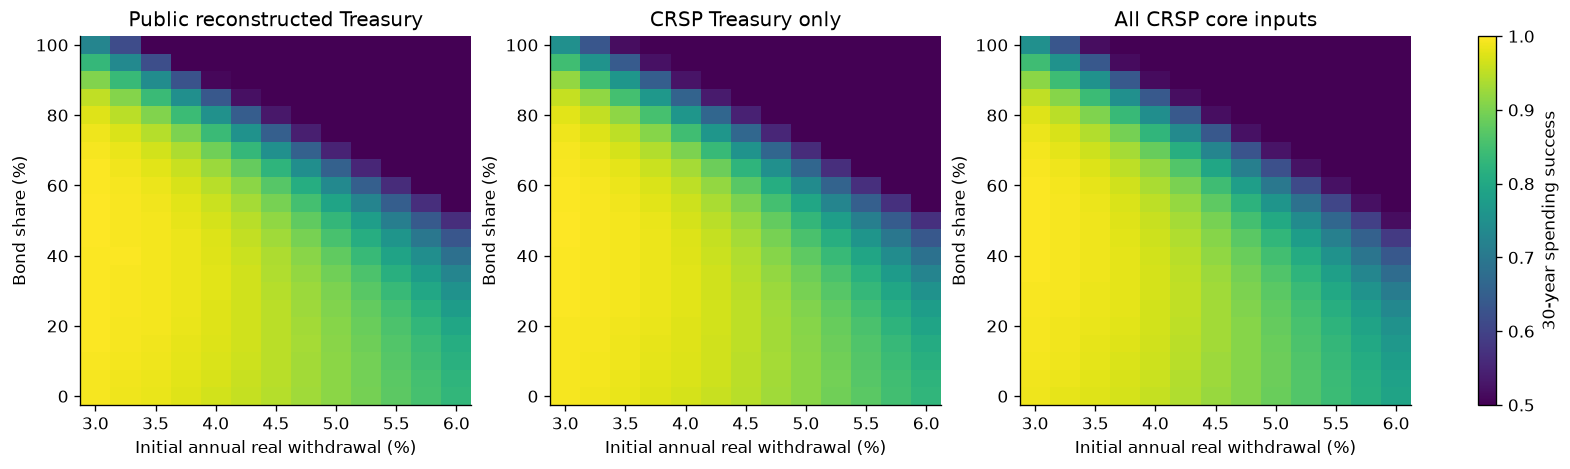

At 5% withdrawals in the 2002-2013 calibration, replacing only Treasury returns increases the highest grid success rate from 89.23% to 90.71%; the first feasible bond allocation is 40%. Over 2002-2024, the all-CRSP panel reaches only 88.73%, below the 90% target. The 40% allocation is therefore conditional on the earlier calibration window, not a general minimum.

,dataset,window,generator,paths,highest_success_at_5pct,minimum_bonds,status
0,public,long,student_t,1000,0.870,NaN,no_feasible_allocation
1,public,modern,student_t,1000,0.926,0.0,no_bonds_needed
2,public,early,student_t,1000,0.877,NaN,no_feasible_allocation
3,public,recent,student_t,1000,0.960,0.0,no_bonds_needed
4,treasury_only,long,student_t,1000,0.873,NaN,no_feasible_allocation
5,treasury_only,modern,student_t,1000,0.927,0.0,no_bonds_needed
6,treasury_only,early,student_t,1000,0.914,0.4,identified
7,treasury_only,recent,student_t,1000,0.966,0.0,no_bonds_needed
8,wrds,long,student_t,1000,0.853,NaN,no_feasible_allocation
9,wrds,modern,student_t,1000,0.901,0.0,no_bonds_needed


The Student-t comparison uses 1,000 paths and a coarser 10-percentage-point bond grid. It can change threshold feasibility and has more Monte Carlo noise than the main experiment; near-90% estimates do not establish a dependable spending guarantee.

In [3]:
rows=[]
for dataset, records in runs.items():
    for window, record in records.items():
        z=result(record)
        for rate in [.04,.045,.05,.055]:
            i=int(np.argmin(abs(np.array(z['r'])-rate)))
            probs=np.array(z['p_success']['30'])[:,i]
            threshold=z['thresholds']['30|0.90'][i]
            boot=z['threshold_bootstrap']['30|0.90'][i]
            rows.append({'dataset':dataset,'window':window,'withdrawal_rate':rate,
                         'best_success':probs.max(),'all_equity_success':probs[0],
                         'minimum_bond_share':threshold['b_min'],'status':threshold['status'],
                         'conditional_bond_q05':boot['q05'],'conditional_bond_q95':boot['q95'],
                         'bootstrap_infeasible_fraction':boot['share_unidentified'],
                         'run_id':record['run_id'],'catalog_hash':record['catalog_hash']})
table=pd.DataFrame(rows)
table.to_csv(OUT/'matched_frontier_summary.csv',index=False)
display(table[np.isclose(table.withdrawal_rate,.05)].round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.4),layout='constrained')
windows=['long','modern','early','recent']
positions=np.arange(len(windows)); width=.25
for j,d in enumerate(labels):
    part=table[np.isclose(table.withdrawal_rate,.05)&table.dataset.eq(d)].set_index('window').loc[windows]
    axes[0].bar(positions+(j-1)*width,100*part.best_success,width,label=labels[d])
    axes[1].plot(positions,100*part.minimum_bond_share,marker='o',label=labels[d])
axes[0].axhline(90,color='black',ls='--',lw=1)
axes[0].set(ylabel='Highest grid success probability (%)',ylim=(75,100),title='5% withdrawal: spending success')
axes[1].set(ylabel='Minimum feasible bond share (%)',ylim=(-5,105),title='90% target; gaps indicate infeasibility')
for ax in axes:
    ax.set_xticks(positions,['1953-2024','2002-2024','2002-2013','2014-2024'],rotation=20)
axes[0].legend(frameon=False,fontsize=8)
export('matched_source_comparison')
fig,axes=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
for ax,d in zip(axes,labels):
    z=result(runs[d]['modern'])
    im=ax.pcolormesh(100*np.array(z['r']),100*np.array(z['b']),z['p_success']['30'],
                     shading='nearest',vmin=.5,vmax=1,cmap='viridis')
    ax.set(title=labels[d],xlabel='Initial annual real withdrawal (%)',ylabel='Bond share (%)')
fig.colorbar(im,ax=axes,label='30-year spending success')
export('matched_success_heatmaps')
early=table[np.isclose(table.withdrawal_rate,.05)&table.window.eq('early')].set_index('dataset')
modern=table[np.isclose(table.withdrawal_rate,.05)&table.window.eq('modern')].set_index('dataset')
display(Markdown(f"At 5% withdrawals in the 2002-2013 calibration, replacing only Treasury returns increases the highest grid success rate from {early.loc['public','best_success']:.2%} to {early.loc['treasury_only','best_success']:.2%}; the first feasible bond allocation is {early.loc['treasury_only','minimum_bond_share']:.0%}. Over 2002-2024, the all-CRSP panel reaches only {modern.loc['wrds','best_success']:.2%}, below the 90% target. The 40% allocation is therefore conditional on the earlier calibration window, not a general minimum."))
alternatives=[]
for d,records in runs.items():
    for window,record in records.items():
        z=result(record)
        i=int(np.argmin(abs(np.array(z['r'])-.05)))
        for generator,alt in z['alt_generators'].items():
            threshold=alt['thresholds'][i]
            alternatives.append({'dataset':d,'window':window,'generator':generator,'paths':alt['n_paths'],
                'highest_success_at_5pct':np.array(alt['p_success'])[:,i].max(),
                'minimum_bonds':threshold['b_min'],'status':threshold['status']})
alternative_table=pd.DataFrame(alternatives)
alternative_table.to_csv(OUT/'generator_sensitivity.csv',index=False)
display(alternative_table.round(4))
display(Markdown('The Student-t comparison uses 1,000 paths and a coarser 10-percentage-point bond grid. It can change threshold feasibility and has more Monte Carlo noise than the main experiment; near-90% estimates do not establish a dependable spending guarantee.'))


## Age, cash flows and independent evaluation

The signed-flow surface fixes an exogenous annual net draw as a fraction of initial reference wealth;
negative values denote contributions. We fit allocations by age and flow using 4,000 paths and evaluate
on 5,000 separate paths, calibrated on January 1953-December 2024 CRSP returns. CRRA risk aversion is 4.
The objective is certainty-equivalent terminal real
wealth plus cumulative funded withdrawals, with a USD 1,000 floor, rather than a direct measure of
household capacity or consumption utility. The age-only rule averages normalized training objectives
equally over the declared flow grid. Joint path resampling preserves dependence across age/flow cells.

The 20-year surface gives ages 25-75 the same effective horizon. With zero labor income in the surface
experiment, age has no independent cash-flow channel there. Age 85 has a 10-year horizon because the
terminal-age cap is 95. Identical fitted allocations for ages 25-75 follow from this model specification.

For historical evaluation, training uses only pre-split returns. Frozen allocations are scored on all
completed later 10- and 20-year cohorts through December 2024. The 1990, 2000, 2005, 2010 and 2015
splits are retained only when the full horizon is available. Public and CRSP versions use the same end
date. Cohorts and splits overlap; their results are reported separately without an IID standard error
or a pooled significance claim. Policies are fixed through each cohort, so this test evaluates static
conditional allocations, not annual adaptive retraining.
Both historical comparisons begin training in May 1953. The separate objective-selection experiment
uses the January 1953-December 2024 CRSP sample, 5,000 training paths and 10,000 evaluation paths.


,delta,lo,hi,n_boot,method
0,0.006128,0.002857,0.010051,300,paired test-path percentile bootstrap across a...


The independent simulation estimate for age-plus-flow versus age-only resources CE is 0.61%, with a paired-path 95% interval [0.29%, 1.01%]. This interval is conditional on the return model and trained policies.

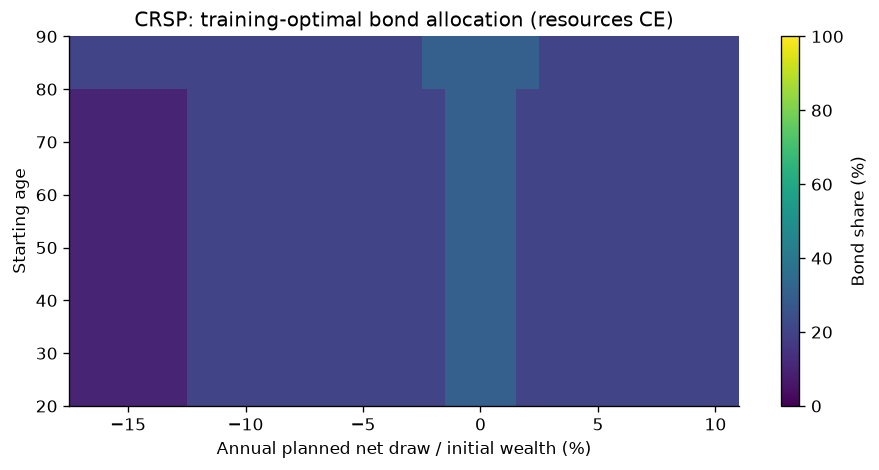

,dataset,split_year,max_horizon,mean_relative_ce,minimum_cell_ce,maximum_cell_ce,cells,minimum_cohorts,maximum_cohorts
0,public_matched,1990,10,0.0182,0.0000,0.0425,24,301,301
1,public_matched,1990,20,-0.0054,-0.0569,0.0425,24,181,301
2,public_matched,2000,10,-0.0096,-0.0337,0.0270,24,181,181
3,public_matched,2000,20,0.0040,-0.0377,0.0511,24,61,181
4,public_matched,2005,10,0.0127,0.0000,0.0422,24,121,121
5,public_matched,2005,20,0.0190,0.0000,0.1268,24,1,121
6,public_matched,2010,10,0.0301,0.0000,0.0934,24,61,61
7,public_matched,2015,10,0.0499,0.0000,0.1066,24,1,1
8,wrds,1990,10,-0.0029,-0.0181,0.0172,24,301,301
9,wrds,1990,20,-0.0015,-0.0280,0.0217,24,181,301


The WRDS chronological mean CE difference is positive in 6 of 8 folds and negative in 2. The range is -0.29% to 4.53%. These overlapping folds are not independent replications; the latest ten-year fold has only one completed cohort.

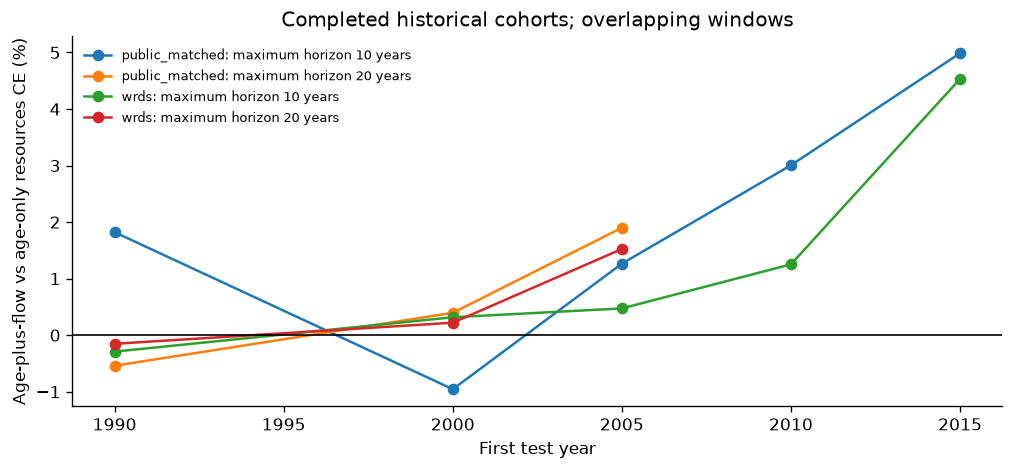

,withdrawal_rate,ce_selected_bonds,success_selected_bonds,ce_policy_success,success_policy_success,ce_gain,ce_ci_lo,ce_ci_hi
0,0.040,0.50,0.30,0.9432,0.9497,0.0546,0.0389,0.0695
1,0.045,0.40,0.25,0.8988,0.9044,0.0434,0.0353,0.0505
2,0.050,0.35,0.05,0.8349,0.8508,0.0969,0.0882,0.1062
3,0.055,0.30,0.05,0.7648,0.7938,0.0518,0.0465,0.0575


At 5% withdrawals, the trained utility policy selects 35% bonds and the spending-success policy selects 5%. On independent paths, the utility policy gains 9.69% CE (95% interval [8.82%, 10.62%]) and changes success by -1.59 percentage points. These objectives recommend different allocations even with the same return data.

In [4]:
signed=result(extended['signed_flow'])
comparison=signed['policies']['oos_full_vs_age']
display(pd.DataFrame([comparison]))
display(Markdown(f"The independent simulation estimate for age-plus-flow versus age-only resources CE is {comparison['delta']:.2%}, with a paired-path 95% interval [{comparison['lo']:.2%}, {comparison['hi']:.2%}]. This interval is conditional on the return model and trained policies."))
fig,ax=plt.subplots(figsize=(9,4))
im=ax.pcolormesh(100*np.array(signed['q']),signed['ages'],100*np.array(signed['b_ce']),shading='nearest',cmap='viridis',vmin=0,vmax=100)
ax.set(xlabel='Annual planned net draw / initial wealth (%)',ylabel='Starting age',title='CRSP: training-optimal bond allocation (resources CE)')
fig.colorbar(im,ax=ax,label='Bond share (%)')
export('age_cash_flow_surface')
history=pd.concat([pd.read_csv(OUT/(d+'_chronological_holdout.csv')) for d in ['wrds','public_matched']],ignore_index=True)
groups=history.groupby(['dataset','split_year','max_horizon']).agg(mean_relative_ce=('full_vs_age_delta','mean'),
    minimum_cell_ce=('full_vs_age_delta','min'),maximum_cell_ce=('full_vs_age_delta','max'),
    cells=('age','size'),minimum_cohorts=('n_overlapping_cohorts','min'),maximum_cohorts=('n_overlapping_cohorts','max')).reset_index()
groups.to_csv(OUT/'chronological_summary.csv',index=False)
display(groups.round(4))
wrds_groups=groups[groups.dataset.eq('wrds')]
display(Markdown(f"The WRDS chronological mean CE difference is positive in {(wrds_groups.mean_relative_ce>0).sum()} of {len(wrds_groups)} folds and negative in {(wrds_groups.mean_relative_ce<0).sum()}. The range is {wrds_groups.mean_relative_ce.min():.2%} to {wrds_groups.mean_relative_ce.max():.2%}. These overlapping folds are not independent replications; the latest ten-year fold has only one completed cohort."))
fig,ax=plt.subplots(figsize=(10,4))
for (d,h),g in groups.groupby(['dataset','max_horizon']):
    ax.plot(g.split_year,100*g.mean_relative_ce,marker='o',label=f'{d}: maximum horizon {h} years')
ax.axhline(0,color='black',lw=1)
ax.set(xlabel='First test year',ylabel='Age-plus-flow vs age-only resources CE (%)',title='Completed historical cohorts; overlapping windows')
ax.legend(frameon=False,fontsize=8)
export('chronological_comparison')
allocation=read('wrds_allocation_holdout.json')
allocation_rows=[]
for r in allocation['results']:
    delta=r['test_ce_delta_ce_vs_survival']
    allocation_rows.append({'withdrawal_rate':r['withdrawal_rate'],'ce_selected_bonds':r['trained_ce_bond_share'],
      'success_selected_bonds':r['trained_survival_bond_share'],'ce_policy_success':r['test_ce_opt_success'],
      'success_policy_success':r['test_survival_opt_success'],'ce_gain':delta['delta'],'ce_ci_lo':delta['lo'],'ce_ci_hi':delta['hi']})
allocation_table=pd.DataFrame(allocation_rows)
allocation_table.to_csv(OUT/'allocation_objective_summary.csv',index=False)
display(allocation_table.round(4))
r5=allocation_table[np.isclose(allocation_table.withdrawal_rate,.05)].iloc[0]
display(Markdown(f"At 5% withdrawals, the trained utility policy selects {r5.ce_selected_bonds:.0%} bonds and the spending-success policy selects {r5.success_selected_bonds:.0%}. On independent paths, the utility policy gains {r5.ce_gain:.2%} CE (95% interval [{r5.ce_ci_lo:.2%}, {r5.ce_ci_hi:.2%}]) and changes success by {(r5.ce_policy_success-r5.success_policy_success)*100:.2f} percentage points. These objectives recommend different allocations even with the same return data."))


## Expanded portfolios and reproducibility

Observed gold, TIPS, high-yield and commodity funds now permit the full multi-asset study and the classic
Permanent Portfolio to execute. The Permanent Portfolio uses the existing annual 15/35 band review and
the same scenario paths as its 60/40 benchmark. The full multi-asset analysis uses 12 sleeves over their
joint available history, with no backfill before fund inception. Results include the source definitions,
costs, common windows, generator and run IDs. Different universes and calibration periods prevent a
causal attribution of changes to diversification alone.


,policy,ce,success_30y,ce_vs_benchmark,lo,hi
0,sixty_forty,20932.2914,0.9480,0.0000,NaN,NaN
1,pp_classic,22104.1346,0.9390,0.0560,-0.0339,0.1310
2,pp_monthly,21029.5709,0.9320,0.0046,-0.0843,0.0796
3,pp_annual,21454.0499,0.9340,0.0249,-0.0656,0.0971
4,pp_15_35_monthly,21999.3927,0.9380,0.0510,-0.0398,0.1253
5,pp_5pp_band,21574.6503,0.9360,0.0307,-0.0617,0.1073
6,pp_intermediate,24659.8915,0.9495,0.1781,0.0884,0.2537
7,pp_tips_blend,23366.2559,0.9435,0.1163,0.0279,0.1907
8,pp_cash_buffer,20800.3017,0.9300,-0.0063,-0.0894,0.0611
9,pp_no_gold,14406.0736,0.7135,-0.3118,-0.3636,-0.2752


,policy,family,ce,success,annual_cost_bps,median_drawdown,relative_ce,lo,hi
0,sixty_forty,static,17258.4842,0.9160,0.1349,-0.2848,0.0000,0.0000,0.0000
1,equal_weight,static,10956.6596,0.5970,0.1960,-0.2798,-0.3651,-0.4020,-0.3342
2,pp_multi_asset,static,9830.4303,0.4000,0.1944,-0.2588,-0.4304,-0.4654,-0.4026
3,risk_parity,static,11103.0756,0.5675,0.1855,-0.2524,-0.3567,-0.3970,-0.3228
4,regime_blocks,regime,17436.7085,0.8640,1.6007,-0.2260,0.0103,-0.0511,0.0609
5,trend_tsmom,trend,9732.1809,0.2840,3.7182,-0.1989,-0.4361,-0.4750,-0.4070
6,inverse_vol,risk,10837.2622,0.5445,1.1541,-0.2572,-0.3721,-0.4115,-0.3417
7,vol_target,risk,10911.9382,0.5280,0.6619,-0.2443,-0.3677,-0.4077,-0.3344
8,crra_static,utility,12991.2378,0.6935,0.1150,-0.2313,-0.2473,-0.2986,-0.2054
9,crra_parametric,utility,12904.7462,0.6915,0.2002,-0.2326,-0.2523,-0.3035,-0.2102


In this calibration, 8 of 9 alternatives have lower consumption CE than 60/40 with an unadjusted paired interval entirely below zero. The intervals condition on the fitted model and are not corrected for multiple policy comparisons. Adding asset classes does not establish superior retirement performance.

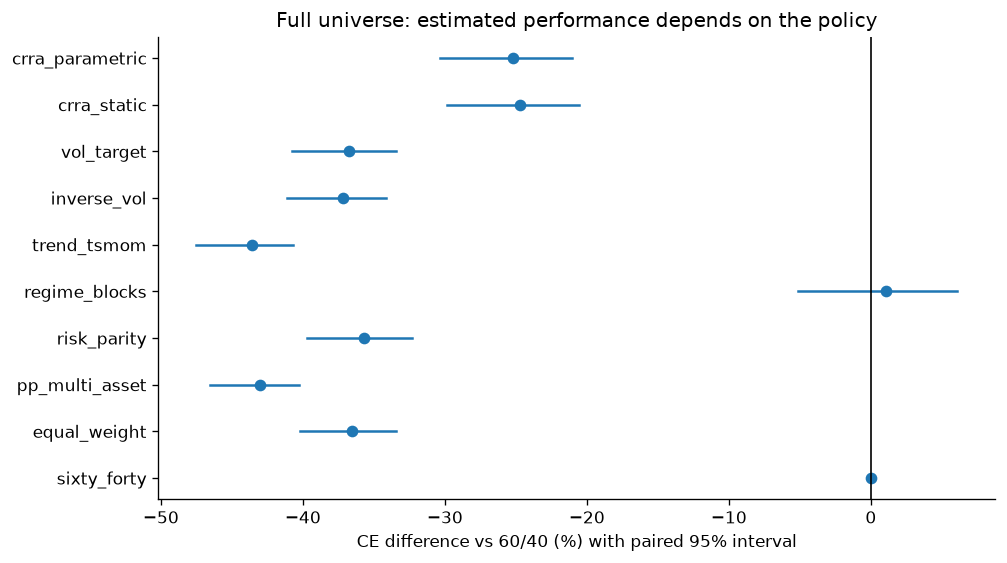

,study,run_id,catalog_hash,engine_version
0,signed_flow,53b2e84a4b9895ad067a,c1f8e3775eab9dd7,0.2.3+f2df1bd6ee98
1,permanent,aa611787c22163372d8c,c1f8e3775eab9dd7,0.2.3+f2df1bd6ee98
2,multi_asset,89516686c41df966361d,c1f8e3775eab9dd7,0.2.3+f2df1bd6ee98


,study,assets,start,end,months
0,permanent,"us_eq, ust_30y, gold, tbill, tips, ust_10y, us...",2004-12-31,2024-12-31,241
1,multi_asset,"us_eq, intl_eq, em_eq, ust_10y, ust_30y, tips,...",2007-05-31,2024-12-31,212


,result
raw_input_hashes,4 of 4 verified
restricted_invalid_return_count,0
nonfinite_values,0
duplicate_month_series_rows,0
matched_frontier_studies,12
frontier_horizon,30 years for success and utility
historical_holdout,8 folds and 192 cells per dataset; 384 cells t...
exact_reproduction,{'frontier': 'reproduced 5ed2a2bb125f27cca2cb'...
backend_tests,111 passed after credit timing correction
restricted_data_in_notebook,No raw vendor observations; aggregate artifact...


In [5]:
pp=result(extended['permanent'])
multi=result(extended['multi_asset'])
pp_rows=[]
for r in pp['scorecard']:
    d=r.get('delta_ce_vs_benchmark',{})
    pp_rows.append({'policy':r['policy'],'ce':r['ce']['ce'],'success_30y':r['success']['30']['p'],
        'ce_vs_benchmark':d.get('delta',0),'lo':d.get('lo'),'hi':d.get('hi')})
display(pd.DataFrame(pp_rows).round(4))
multi_rows=[]
for r in multi['scorecard']:
    delta=r.get('delta_ce',{})
    multi_rows.append({'policy':r['policy'],'family':r['family'],'ce':r['ce'],
                      'success':r['success'],'annual_cost_bps':r['cost_bps_yr'],'median_drawdown':r['mdd_median'],
                      'relative_ce':delta.get('delta',0),'lo':delta.get('lo',0),'hi':delta.get('hi',0)})
multi_table=pd.DataFrame(multi_rows)
display(multi_table.round(4))
display(Markdown(f"In this calibration, {(multi_table.hi<0).sum()} of {len(multi_table)-1} alternatives have lower consumption CE than 60/40 with an unadjusted paired interval entirely below zero. The intervals condition on the fitted model and are not corrected for multiple policy comparisons. Adding asset classes does not establish superior retirement performance."))
multi_table.to_csv(OUT/'multi_asset_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
for i,r in multi_table.iterrows():
    ax.plot([100*r['lo'],100*r['hi']],[i,i],color='tab:blue')
    ax.plot(100*r.relative_ce,i,'o',color='tab:blue')
ax.axvline(0,color='black',lw=1)
ax.set_yticks(range(len(multi_table)),multi_table.policy)
ax.set(xlabel='CE difference vs 60/40 (%) with paired 95% interval',title='Full universe: estimated performance depends on the policy')
export('multi_asset_comparison')
display(pd.DataFrame([{'study':name,'run_id':record['run_id'],'catalog_hash':record['catalog_hash'],
    'engine_version':record['engine_version']} for name,record in extended.items()]))
display(pd.DataFrame([{'study':name,'assets':', '.join(z['universe']['assets']),
                      'start':z['universe']['window'][0],'end':z['universe']['window'][1],
                     'months':z['universe']['n_months']}
                     for name,z in [('permanent',pp),('multi_asset',multi)]]))
display(pd.DataFrame([read('verification.json')]).T.rename(columns={0:'result'}))


## Interpretation and remaining limits

Return measurement changes the estimated spending-success frontier enough to change whether a 90%
target is feasible. The result also changes across historical windows. A universal bond allocation or
withdrawal guarantee is unsupported by these experiments. The age-plus-flow comparison must be judged
from its independent-path and chronological results above; separating the concepts of willingness and
capacity is a modeling premise, not an empirical finding from these market data.

All simulations condition on historical calibration, the withdrawal convention, CRRA objective,
rebalancing rule and terminal-age cap. Bootstrap and Student-t experiments do not eliminate structural
model risk. Historical tests use revised data extracts, overlapping cohorts and selected windows.
Monte Carlo intervals measure simulation uncertainty. Country effects, cohort effects, human-capital
risk and changes in household preferences remain outside this return-based extension.

The notebook is executable from the supplied aggregate JSON and CSV artifacts without a WRDS account.
Recomputing the restricted-data studies requires an entitled WRDS academic account. Run
`research/extract_wrds_cloud.py` in WRDS Cloud, retain the exported files locally under
`data/wrds_validation/inputs`, then run these commands from the repository root:

```powershell
backend/.venv/Scripts/python.exe research/import_wrds_cloud.py
backend/.venv/Scripts/python.exe research/validate_wrds_followup.py --dataset public
backend/.venv/Scripts/python.exe research/validate_wrds_followup.py --dataset treasury_only
backend/.venv/Scripts/python.exe research/validate_wrds_followup.py --dataset wrds
```

`public_matched_chronological_holdout.csv` is generated by calling
`validate_followup.holdout('public_matched', end_date='2024-12-31', start_date='1953-05-01')`
with the public data directory.
Hashes identify the exact restricted extracts and resolved panels; vendor revisions can change a fresh
extraction. The delivered package contains no restricted return observations. WRDS access has been
completed. Employer installation still awaits the employer's reply and GitHub username; no message has
been sent on the user's behalf.
